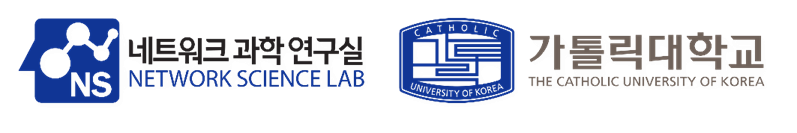


# Solution 5: Deeper GNNs

## Setup

In [1]:
import math, time, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.datasets import Planetoid
from torch_geometric.utils import to_dense_adj

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)

Device: cuda


# Use the Cora dataset. Do below assignments.

# Assignment 1. Diagnose over-smoothing.

Questions:

1) Show some graph statistics of the graph, i.e., number of nodes, number of edges, number of connected components, and the degree distribution.
2) Implement the **Dirichlet energy** $E(H)=\operatorname{tr}(H^\top\tilde L H)$ (and its scale-free version $E(H)/\|H\|_F^2$) and the **MAD** (mean average cosine distance) metrics from the lecture.
3) Compute $\hat A^k X$ for $k = 0, 1, 2, 4, \dots, 128$ and plot both metrics against $k$.
4) Train a plain GCN with 2, 4, 8, 16 and 32 layers (3 random seeds each) and plot the test accuracy against depth. Then plot the Dirichlet energy and MAD of **every hidden layer** of a 64-layer GCN (at initialisation and after training).
5) Explain the results using the spectral view of over-smoothing (the filter $(1-\lambda_i)^l$).

### 1) Graph statistics

In [2]:
# Import dataset from PyTorch Geometric
dataset = Planetoid(root=".", name="Cora")

data = dataset[0]

In [3]:
# Print information about the dataset
print(f'Dataset: {dataset}')
print('-------------------')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of nodes: {data.x.shape[0]}')
print(f'Number of edges: {data.edge_index.shape[1]} (directed) = {data.edge_index.shape[1] // 2} undirected')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')
print(f'Train / Val / Test nodes: {int(data.train_mask.sum())} / {int(data.val_mask.sum())} / {int(data.test_mask.sum())}')

# Print information about the graph
print(f'\nGraph:')
print('------')
print(f'Edges are directed: {data.is_directed()}')
print(f'Graph has isolated nodes: {data.has_isolated_nodes()}')
print(f'Graph has loops: {data.has_self_loops()}')

Dataset: Cora()
-------------------
Number of graphs: 1
Number of nodes: 2708
Number of edges: 10556 (directed) = 5278 undirected
Number of features: 1433
Number of classes: 7
Train / Val / Test nodes: 140 / 500 / 1000

Graph:
------
Edges are directed: False
Graph has isolated nodes: False
Graph has loops: False


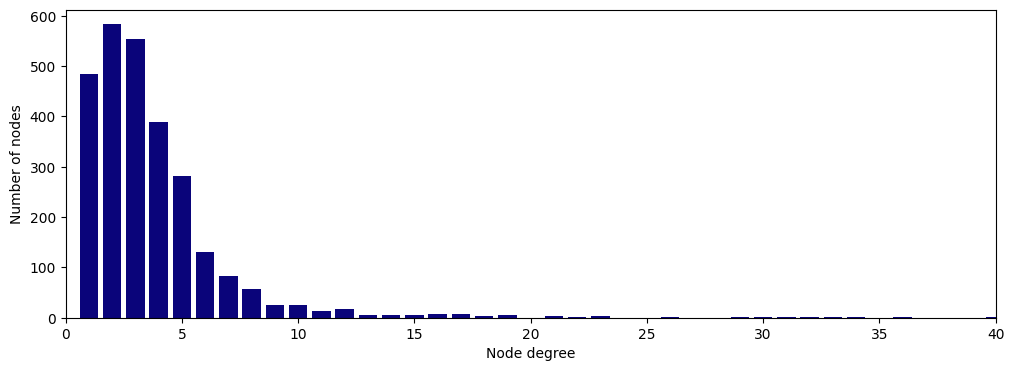

Max degree: 168 | Mean degree: 3.90
Connected components: 78 | Largest component: 2485 nodes


In [4]:
from torch_geometric.utils import degree
from collections import Counter

# Get list of degrees for each node
degrees = degree(data.edge_index[0], num_nodes=data.num_nodes).numpy()

# Count the number of nodes for each degree
numbers = Counter(degrees)

# Bar plot
fig, ax = plt.subplots(figsize=(12, 4))
ax.set_xlabel('Node degree')
ax.set_ylabel('Number of nodes')
ax.set_xlim(0, 40)
plt.bar(numbers.keys(), numbers.values(), color='#0A047A')
plt.show()

G_nx = nx.Graph()
G_nx.add_nodes_from(range(data.num_nodes))
G_nx.add_edges_from(data.edge_index.t().tolist())
components = list(nx.connected_components(G_nx))
print(f'Max degree: {int(degrees.max())} | Mean degree: {degrees.mean():.2f}')
print(f'Connected components: {len(components)} | Largest component: {max(len(c) for c in components)} nodes')

In [5]:
# Dense tensors used by every model in this notebook
N = data.num_nodes
num_features, num_classes = dataset.num_features, dataset.num_classes

X = data.x.to(device)
X = X / X.sum(dim=1, keepdim=True).clamp(min=1)          # row-normalise the bag-of-words features
y = data.y.to(device)
train_mask = data.train_mask.to(device)
val_mask = data.val_mask.to(device)
test_mask = data.test_mask.to(device)

# Binary, symmetric adjacency matrix without self-loops
A = to_dense_adj(data.edge_index, max_num_nodes=N)[0].to(device)
A = ((A + A.t()) > 0).float()
A.fill_diagonal_(0)

def normalize_adj(A, self_loops=True):
    """GCN propagation matrix  Â = D̃^{-1/2} (A + I) D̃^{-1/2}  (dense)."""
    if self_loops:
        A = A + torch.eye(A.size(0), device=A.device)
    deg = A.sum(dim=1)
    d_inv_sqrt = deg.pow(-0.5)
    d_inv_sqrt[torch.isinf(d_inv_sqrt)] = 0.
    return d_inv_sqrt[:, None] * A * d_inv_sqrt[None, :]

A_hat = normalize_adj(A)
print('A:', tuple(A.shape), '| undirected edges:', int(A.sum().item() // 2))

A: (2708, 2708) | undirected edges: 5278


### 2) Dirichlet energy and MAD

In [6]:
def dirichlet_energy(H, A_hat, normalized=False):
    """Dirichlet energy  E(H) = tr(Hᵀ L̃ H) / N  with  L̃ = I - Â  (slide 20).
    E -> 0 means the representations are constant over every edge (over-smoothing).
    normalized=True returns the scale-free version tr(Hᵀ L̃ H) / ‖H‖²_F (Rayleigh quotient, in [0, 2]),
    which separates 'smoothing' from 'the features just shrink'. Computed in float64 (tiny values in deep nets)."""
    H = H.double()
    energy = (H * (H - A_hat.double() @ H)).sum().item()
    if normalized:
        norm2 = H.pow(2).sum().item()
        return energy / norm2 if norm2 > 0 else 0.0
    return energy / H.size(0)

def mad(H):
    """Mean Average Distance: mean cosine distance 1 - h_i·h_j / (‖h_i‖‖h_j‖) over all node pairs (slide 20)."""
    H = H.double()
    H = H[H.abs().sum(dim=1) > 0]                       # ignore all-zero (dead) rows
    if H.size(0) < 2:
        return 0.0
    H = H / H.abs().max(dim=1, keepdim=True)[0]         # rescale rows first to avoid underflow
    Hn = F.normalize(H, dim=1)
    n = H.size(0)
    return ((1 - Hn @ Hn.t()).clamp(min=0).sum() / (n * (n - 1))).item()

### 3) Pure propagation $\hat A^k X$

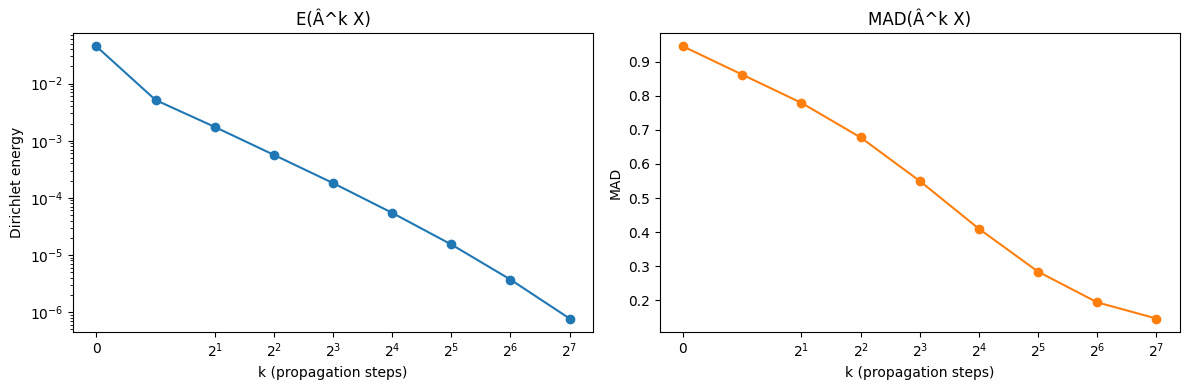

k =   0 | Dirichlet energy = 4.48e-02 | MAD = 0.9442
k =   1 | Dirichlet energy = 5.16e-03 | MAD = 0.8615
k =   2 | Dirichlet energy = 1.75e-03 | MAD = 0.7789
k =   4 | Dirichlet energy = 5.65e-04 | MAD = 0.6776
k =   8 | Dirichlet energy = 1.81e-04 | MAD = 0.5501
k =  16 | Dirichlet energy = 5.45e-05 | MAD = 0.4101
k =  32 | Dirichlet energy = 1.52e-05 | MAD = 0.2845
k =  64 | Dirichlet energy = 3.70e-06 | MAD = 0.1946
k = 128 | Dirichlet energy = 7.68e-07 | MAD = 0.1472


In [7]:
# Pure propagation  H^(k) = Â^k X  (no weights, no non-linearity)
ks = [0, 1, 2, 4, 8, 16, 32, 64, 128]
energies, mads = [], []
H = X.clone()
for k in range(max(ks) + 1):
    if k in ks:
        energies.append(dirichlet_energy(H, A_hat))
        mads.append(mad(H))
    H = A_hat @ H

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(ks, energies, 'o-'); ax[0].set_xscale('symlog', base=2)
ax[0].set_xlabel('k (propagation steps)'); ax[0].set_ylabel('Dirichlet energy'); ax[0].set_title('E(Â^k X)')
ax[1].plot(ks, mads, 'o-', color='C1'); ax[1].set_xscale('symlog', base=2)
ax[1].set_xlabel('k (propagation steps)'); ax[1].set_ylabel('MAD'); ax[1].set_title('MAD(Â^k X)')
plt.tight_layout(); plt.show()
for k, e, m in zip(ks, energies, mads):
    print(f'k = {k:>3} | Dirichlet energy = {e:.2e} | MAD = {m:.4f}')

### 4) Plain GCN with increasing depth

In [8]:
def accuracy(pred_y, y):
    """Calculate accuracy."""
    return (pred_y == y).float().mean().item()

def train_model(model, inputs, epochs=300, lr=0.01, weight_decay=5e-4, optimizer=None,
                train_inputs_fn=None, split=None, patience=100, log_every=50, verbose=True):
    """Full-batch training with early stopping on validation accuracy.

    inputs          : tuple, the model is called as model(*inputs) for evaluation
    train_inputs_fn : optional callable returning *training-time* inputs (e.g. a DropEdge graph)
    split           : optional (y, train_mask, val_mask, test_mask); defaults to the Cora split
    Returns (best validation accuracy, test accuracy at the best validation epoch)."""
    yy, tr_m, va_m, te_m = split if split is not None else (y, train_mask, val_mask, test_mask)
    model = model.to(device)
    if optimizer is None:
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_test, best_epoch, bad, best_state = 0., 0., 0, 0, None

    for epoch in range(1, epochs + 1):
        # Training
        model.train()
        optimizer.zero_grad()
        out = model(*(train_inputs_fn() if train_inputs_fn is not None else inputs))
        loss = F.cross_entropy(out[tr_m], yy[tr_m])
        loss.backward()
        optimizer.step()

        # Validation / test
        model.eval()
        with torch.no_grad():
            out = model(*inputs)
            val_loss = F.cross_entropy(out[va_m], yy[va_m]).item()
            pred = out.argmax(dim=1)
            train_acc, val_acc, test_acc = (accuracy(pred[m], yy[m]) for m in (tr_m, va_m, te_m))

        if val_acc > best_val:
            best_val, best_test, best_epoch, bad = val_acc, test_acc, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1

        if verbose and (epoch == 1 or epoch % log_every == 0):
            print(f'Epoch {epoch:>3} | Train Loss: {loss:.3f} | Train Acc: {train_acc*100:>6.2f}% | '
                  f'Val Loss: {val_loss:.2f} | Val Acc: {val_acc*100:.2f}%')
        if bad >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)          # keep the best-validation weights
    if verbose:
        print(f'>> Best epoch {best_epoch} | Val Acc: {best_val*100:.2f}% | Test Acc: {best_test*100:.2f}%')
    return best_val, best_test

def repeat(make_model, inputs, seeds=(0, 1, 2), make_optimizer=None, **kwargs):
    """Train a fresh model for every seed; returns mean and std of the test accuracy."""
    accs = []
    for seed in seeds:
        set_seed(seed)
        model = make_model()
        optimizer = make_optimizer(model) if make_optimizer is not None else None
        accs.append(train_model(model, inputs, optimizer=optimizer, verbose=False, **kwargs)[1])
    return float(np.mean(accs)), float(np.std(accs))

results = {}   # model name -> test accuracy (filled throughout the notebook)

In [9]:
class GCNLayer(nn.Module):
    """Dense Kipf & Welling layer:  H' = Â H W + b."""
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_features))

    def forward(self, x, adj):
        return adj @ self.linear(x) + self.bias

class GCN(nn.Module):
    """Plain L-layer GCN. `norm` (e.g. PairNorm) and `residual` are optional add-ons used later."""
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers=2, dropout=0.5, norm=None, residual=False):
        super().__init__()
        dims = [in_dim] + [hidden_dim] * (num_layers - 1) + [out_dim]
        self.layers = nn.ModuleList([GCNLayer(dims[i], dims[i + 1]) for i in range(num_layers)])
        self.norm = norm
        self.residual = residual
        self.dropout = dropout

    def forward(self, x, adj):
        self.hidden = []                          # hidden representations, used for layer-wise metrics
        for i, layer in enumerate(self.layers):
            x_in = x
            x = F.dropout(x, self.dropout, self.training)
            x = layer(x, adj)
            if i < len(self.layers) - 1:          # hidden layers
                if self.norm is not None:
                    x = self.norm(x)
                x = F.relu(x)
                if self.residual and x.shape == x_in.shape:
                    x = x + x_in
                self.hidden.append(x)
        return x

In [10]:
%%time
set_seed(0)
gcn = GCN(num_features, 64, num_classes, num_layers=2)
print(gcn)
_, results['GCN (2 layers)'] = train_model(gcn, (X, A_hat))

GCN(
  (layers): ModuleList(
    (0): GCNLayer(
      (linear): Linear(in_features=1433, out_features=64, bias=False)
    )
    (1): GCNLayer(
      (linear): Linear(in_features=64, out_features=7, bias=False)
    )
  )
)
Epoch   1 | Train Loss: 1.946 | Train Acc:  37.86% | Val Loss: 1.95 | Val Acc: 17.20%
Epoch  50 | Train Loss: 0.766 | Train Acc:  98.57% | Val Loss: 1.15 | Val Acc: 78.00%
Epoch 100 | Train Loss: 0.346 | Train Acc:  99.29% | Val Loss: 0.86 | Val Acc: 78.20%
Epoch 150 | Train Loss: 0.288 | Train Acc: 100.00% | Val Loss: 0.76 | Val Acc: 78.80%
>> Best epoch 60 | Val Acc: 80.60% | Test Acc: 82.70%
CPU times: user 5.02 s, sys: 69.9 ms, total: 5.09 s
Wall time: 5.09 s


GCN  2 layers | Test Acc: 82.53% ± 0.17
GCN  4 layers | Test Acc: 73.93% ± 1.39
GCN  8 layers | Test Acc: 15.40% ± 0.54
GCN 16 layers | Test Acc: 28.67% ± 4.57
GCN 32 layers | Test Acc: 19.23% ± 2.33


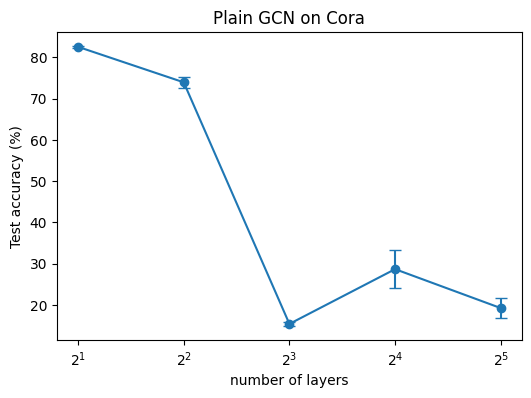

CPU times: user 50.5 s, sys: 133 ms, total: 50.7 s
Wall time: 50.5 s


In [11]:
%%time
# Test accuracy vs. depth (mean ± std over 3 seeds)
depths = [2, 4, 8, 16, 32]
depth_acc = {}
for L in depths:
    depth_acc[L] = repeat(lambda: GCN(num_features, 64, num_classes, num_layers=L), (X, A_hat), epochs=200)
    print(f'GCN {L:>2} layers | Test Acc: {depth_acc[L][0]*100:.2f}% ± {depth_acc[L][1]*100:.2f}')

plt.figure(figsize=(6, 4))
plt.errorbar(depths, [depth_acc[L][0] * 100 for L in depths], yerr=[depth_acc[L][1] * 100 for L in depths],
             fmt='o-', capsize=4)
plt.xscale('log', base=2); plt.xlabel('number of layers'); plt.ylabel('Test accuracy (%)')
plt.title('Plain GCN on Cora'); plt.show()

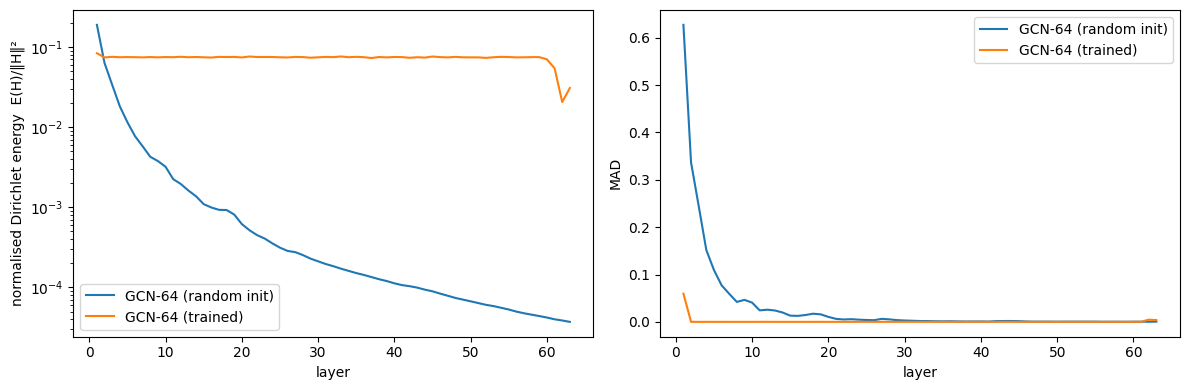

In [12]:
def layerwise_metrics(model):
    """Normalised Dirichlet energy and MAD of every hidden layer of a GCN (eval mode, no dropout)."""
    model = model.to(device).eval()
    with torch.no_grad():
        model(X, A_hat)
    return [dirichlet_energy(h, A_hat, normalized=True) for h in model.hidden], [mad(h) for h in model.hidden]

def plot_layerwise(models):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for name, model in models.items():
        E, M = layerwise_metrics(model)
        layers = range(1, len(E) + 1)
        ax[0].semilogy(layers, E, label=name)
        ax[1].plot(layers, M, label=name)
    ax[0].set_ylabel('normalised Dirichlet energy  E(H)/‖H‖²'); ax[1].set_ylabel('MAD')
    for a in ax:
        a.set_xlabel('layer'); a.legend()
    plt.tight_layout(); plt.show()

# Hidden representations of a 64-layer GCN, (a) at random initialisation and (b) after training
set_seed(0)
gcn64_init = GCN(num_features, 64, num_classes, num_layers=64)
set_seed(0)
gcn64_trained = GCN(num_features, 64, num_classes, num_layers=64)
train_model(gcn64_trained, (X, A_hat), epochs=200, verbose=False)
plot_layerwise({'GCN-64 (random init)': gcn64_init, 'GCN-64 (trained)': gcn64_trained})

### 5) Spectral explanation

Number of (numerically) zero eigenvalues = number of connected components: 78


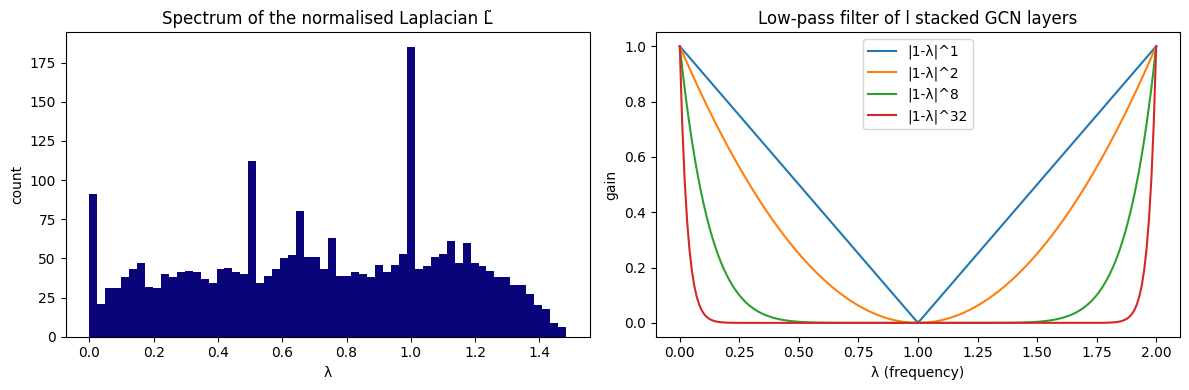

In [13]:
# Spectral view (slide 19): Â = I - L̃ multiplies the i-th eigen-component by (1 - λ_i) at every layer
L_tilde = torch.eye(N, device=device) - A_hat
evals = torch.linalg.eigvalsh(L_tilde.double()).float().cpu()
print(f'Number of (numerically) zero eigenvalues = number of connected components: {(evals < 1e-6).sum().item()}')

lam = torch.linspace(0, 2, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(evals.numpy(), bins=60, color='#0A047A'); ax[0].set_title('Spectrum of the normalised Laplacian L̃')
ax[0].set_xlabel('λ'); ax[0].set_ylabel('count')
for l in [1, 2, 8, 32]:
    ax[1].plot(lam, (1 - lam).abs() ** l, label=f'|1-λ|^{l}')
ax[1].set_xlabel('λ (frequency)'); ax[1].set_ylabel('gain'); ax[1].set_title('Low-pass filter of l stacked GCN layers')
ax[1].legend(); plt.tight_layout(); plt.show()

### Answers 

1) Statistics. Cora has 2,708 nodes, 5,278 undirected edges, 1,433 bag-of-words features, and 7 classes. There are no self-loops or isolated nodes, but the graph has 78 connected components (the largest has 2,485 nodes). The degree distribution is heavy-tailed: mean degree 3.9, maximum 168.

3) Pure propagation. For $\hat A^kX$ the Dirichlet energy drops from $4.5\cdot10^{-2}$ ($k=0$) to $7.7\cdot10^{-7}$ ($k=128$), and the MAD drops from 0.94 to 0.15. Repeated multiplication by $\hat A$ drives every connected component towards the dominant eigenvector, where node $i$'s features are proportional to $\sqrt{\tilde d_i}$. MAD does not reach exactly 0 because each of the 78 components converges to its own limit.

4) Trained GCNs. Test accuracy (3 seeds) is 82.5% (2 layers), 73.9% (4 layers), and then 15–29% for 8, 16 and 32 layers. That is chance level: the model predicts roughly one class.
- The layer-wise plot of the 64-layer GCN shows the collapse directly. At initialisation the normalised energy falls by about four orders of magnitude, and MAD reaches about 0 around layer 20.
- After training, MAD is 0 from the 2nd layer on, so all hidden vectors point in the same direction. The normalised energy stays at a constant ≈0.075. It is not 0 because the rows are scaled by the node degree: this is exactly the stationary limit of slide 18 (features ∝ √degree).
- Training cannot escape this state because the gradients through 64 stacked weight matrices vanish (slide 34).

5) Spectral explanation. $\hat A = I-\tilde L$ has eigenvalues $1-\lambda_i\in(-1,1]$, so after $l$ layers the $i$-th spectral component of the signal is multiplied by $(1-\lambda_i)^l$.
- As the second plot shows, the pass-band of $|1-\lambda|^l$ shrinks towards $\lambda=0$ as $l$ grows.
- Only the $\lambda=0$ eigenvectors survive, one per connected component: 78 zero eigenvalues here. All high-frequency information, i.e. the differences between neighbouring nodes that separate the classes, is removed exponentially fast.
- The weights $W$ act on the feature dimension, not on the node dimension, so unless they are large they cannot restore what $\hat A^l$ removed (Oono & Suzuki, 2020).
- Over-smoothing and vanishing gradients together explain why the best plain GCN on Cora has 2 layers.

# Assignment 2. Skip connections and normalisation on a deep GCN.

Questions:

1) Implement (from scratch) the DeepGCNs ResGCN / res+ block and GCNII (initial residual + identity mapping).
2) Implement PairNorm and DropEdge.
3) With 32 layers, train: plain GCN, GCN + residual, DeepGCN (res+), GCNII, GCN + PairNorm (with the residual update of the lecture), GCN + DropEdge. Report the test accuracy (mean ± std over 3 seeds) and the (normalised) Dirichlet energy / MAD for each model.
4) For GCNII, vary $\alpha \in \{0, 0.1, 0.5\}$ and $\lambda \in \{0.1, 0.5, 1.0\}$ (with $\beta_\ell=\log(\lambda/\ell+1)$). What happens when $\alpha = 0$?
5) Which of these methods address over-smoothing, and which mainly address optimisation/overfitting? Explain.

### 1) DeepGCNs (res+) and GCNII

In [14]:
class GENConv(nn.Module):
    """Generalised aggregation layer of DeeperGCN (SoftMax_Agg):
         m_j  = ReLU(h_j) + ε
         a_i  = Σ_{j∈N(i)} softmax_j(t · m_j) · m_j        (per channel, t learnable)
         h_i' = MLP(h_i + a_i)
    t -> 0 gives mean aggregation, t -> ∞ gives max aggregation."""
    def __init__(self, in_dim, out_dim, t=1.0, learn_t=True, eps=1e-7):
        super().__init__()
        self.t = nn.Parameter(torch.tensor([t])) if learn_t else t
        self.eps = eps
        self.mlp = nn.Sequential(nn.Linear(in_dim, 2 * in_dim), nn.LayerNorm(2 * in_dim),
                                 nn.ReLU(), nn.Linear(2 * in_dim, out_dim))

    def forward(self, x, adj):
        # adj is the *binary* adjacency. The softmax weight of a message only depends on the source
        # node j and the channel, so the per-node softmax is two dense mat-muls (numerator / denominator).
        m = F.relu(x) + self.eps
        logits = self.t * m
        w = torch.exp(logits - logits.max(dim=0, keepdim=True)[0])   # numerically stable
        agg = (adj @ (w * m)) / (adj @ w).clamp(min=1e-16)
        return self.mlp(x + agg)

class DeepGCNLayer(nn.Module):
    """Backbone blocks of DeepGCNs (slides 37-39):
       'plain' : x' = act(norm(conv(x)))
       'res'   : x' = x + act(norm(conv(x)))                  (ResGCN)
       'res+'  : x' = x + conv(dropout(act(norm(x))))         (pre-activation residual, DeeperGCN)
       'dense' : x' = [x || act(norm(conv(x)))]               (DenseGCN)"""
    def __init__(self, conv, norm, block='res+', dropout=0.1):
        super().__init__()
        self.conv, self.norm, self.block, self.dropout = conv, norm, block, dropout

    def forward(self, x, adj):
        if self.block == 'res+':
            h = F.dropout(F.relu(self.norm(x)), self.dropout, self.training)
            return x + self.conv(h, adj)
        h = F.dropout(F.relu(self.norm(self.conv(x, adj))), self.dropout, self.training)
        if self.block == 'res':
            return x + h
        if self.block == 'dense':
            return torch.cat([x, h], dim=1)
        return h                                              # plain

class DeepGCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers=16, block='res+', dropout=0.1, growth=16):
        super().__init__()
        self.encoder = nn.Linear(in_dim, hidden_dim)
        self.layers = nn.ModuleList()
        dim = hidden_dim
        for _ in range(num_layers):
            out = growth if block == 'dense' else hidden_dim
            conv = GENConv(dim, out)
            norm = nn.LayerNorm(dim if block == 'res+' else out)
            self.layers.append(DeepGCNLayer(conv, norm, block, dropout))
            dim = dim + growth if block == 'dense' else dim
        self.final_norm = nn.LayerNorm(dim)
        self.classifier = nn.Linear(dim, out_dim)
        self.dropout = dropout

    def forward(self, x, adj):
        x = F.dropout(x, 0.5, self.training)
        x = self.encoder(x)
        for layer in self.layers:
            x = layer(x, adj)
        x = F.dropout(F.relu(self.final_norm(x)), 0.5, self.training)
        return self.classifier(x)

In [15]:
class GCNIILayer(nn.Module):
    """H' = σ( ((1-α) Â H + α H⁰) ((1-β) I + β W) )   (slide 43)
       initial residual : α H⁰ keeps a fraction of the input representation in every layer
       identity mapping : (1-β) I + β W keeps the layer close to the identity when β is small"""
    def __init__(self, channels):
        super().__init__()
        self.weight = nn.Linear(channels, channels, bias=False)

    def forward(self, h, h0, adj, alpha, beta):
        support = (1 - alpha) * (adj @ h) + alpha * h0           # initial residual
        return (1 - beta) * support + beta * self.weight(support) # identity mapping

class GCNII(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers=64, alpha=0.1, lamda=0.5, dropout=0.6):
        super().__init__()
        self.fc_in = nn.Linear(in_dim, hidden_dim)
        self.convs = nn.ModuleList([GCNIILayer(hidden_dim) for _ in range(num_layers)])
        self.fc_out = nn.Linear(hidden_dim, out_dim)
        self.alpha, self.lamda, self.dropout = alpha, lamda, dropout

    def forward(self, x, adj):
        x = F.dropout(x, self.dropout, self.training)
        h0 = F.relu(self.fc_in(x))
        h = h0
        for l, conv in enumerate(self.convs, start=1):
            beta = math.log(self.lamda / l + 1)                 # β_l = log(λ/l + 1) decays with depth
            h = F.dropout(h, self.dropout, self.training)
            h = F.relu(conv(h, h0, adj, self.alpha, beta))
        h = F.dropout(h, self.dropout, self.training)
        return self.fc_out(h)

def gcnii_optimizer(model, lr=0.01):
    # As in the paper: strong L2 on the propagation weights, weak L2 on the dense input/output layers
    return torch.optim.Adam([
        dict(params=model.convs.parameters(), weight_decay=0.01),
        dict(params=list(model.fc_in.parameters()) + list(model.fc_out.parameters()), weight_decay=5e-4),
    ], lr=lr)

### 2) PairNorm and DropEdge

In [16]:
class PairNorm(nn.Module):
    """PairNorm (slide 51):
         center : x̃_i^c = x̃_i - (1/n) Σ_i x̃_i
         scale  : ẋ_i   = s · √n · x̃_i^c / ‖X̃^c‖_F = s · x̃_i^c / sqrt((1/n) Σ_i ‖x̃_i^c‖²)
       keeps the total pairwise squared distance constant from layer to layer.
       mode 'PN-SI' scales every node individually, 'PN-SCS' scales individually then centers."""
    def __init__(self, mode='PN', scale=1.0, eps=1e-6):
        super().__init__()
        self.mode, self.scale, self.eps = mode, scale, eps

    def forward(self, x):
        if self.mode == 'PN-SCS':
            x = self.scale * x / (self.eps + x.norm(dim=1, keepdim=True))
            return x - x.mean(dim=0, keepdim=True)
        x = x - x.mean(dim=0, keepdim=True)                                   # center
        if self.mode == 'PN':
            return self.scale * x / (self.eps + x.pow(2).sum(dim=1).mean()).sqrt()
        return self.scale * x / (self.eps + x.norm(dim=1, keepdim=True))     # PN-SI

In [17]:
def drop_edge(A, p=0.3):
    """DropEdge: remove every undirected edge independently with probability p (Bernoulli mask).
    Must be re-sampled at every training epoch; the full graph is used at test time."""
    keep = (torch.rand_like(A) > p).float().triu(diagonal=1)
    keep = keep + keep.t()                                  # keep the graph symmetric
    return A * keep

A_drop = drop_edge(A, p=0.3)
print(f'Edges before: {int(A.sum()) // 2} | after DropEdge(p=0.3): {int(A_drop.sum()) // 2}')

Edges before: 5278 | after DropEdge(p=0.3): 3757


### 3) 32-layer comparison

In [18]:
%%time
L = 32
deep_models = {
    'GCN (plain)':       (lambda: GCN(num_features, 64, num_classes, num_layers=L), A_hat, None, None),
    'DeepGCN (ResGCN+)': (lambda: DeepGCN(num_features, 64, num_classes, num_layers=L, block='res+'), A, None, None),
    'GCNII':             (lambda: GCNII(num_features, 64, num_classes, num_layers=L), A_hat, 'gcnii', None),
    'GCN + residual':    (lambda: GCN(num_features, 64, num_classes, num_layers=L, residual=True), A_hat, None, None),
    'GCN + PairNorm':    (lambda: GCN(num_features, 64, num_classes, num_layers=L, norm=PairNorm('PN'), residual=True),
                          A_hat, None, None),
    'GCN + DropEdge':    (lambda: GCN(num_features, 64, num_classes, num_layers=L), A_hat, None,
                          lambda: (X, normalize_adj(drop_edge(A, p=0.5)))),
}
deep_stats = {}
trained = {}
for name, (make, adj, opt, train_fn) in deep_models.items():
    accs = []
    for seed in (0, 1, 2):
        set_seed(seed)
        model = make()
        optimizer = gcnii_optimizer(model) if opt == 'gcnii' else None
        accs.append(train_model(model, (X, adj), epochs=400, optimizer=optimizer, train_inputs_fn=train_fn,
                                verbose=False)[1])
    model.eval()
    with torch.no_grad():
        out = model(X, adj)
    trained[name] = model
    deep_stats[name] = (np.mean(accs), np.std(accs), dirichlet_energy(out, A_hat, normalized=True), mad(out))
    print(f'{name:<18} | {L} layers | Test Acc: {np.mean(accs)*100:.2f}% ± {np.std(accs)*100:.2f} | '
          f'normalised Dirichlet energy (output): {deep_stats[name][2]:.4f} | MAD (output): {deep_stats[name][3]:.4f}')

for name in ['DeepGCN (ResGCN+)', 'GCNII', 'GCN + PairNorm', 'GCN + DropEdge']:
    results[name] = deep_stats[name][0]

GCN (plain)        | 32 layers | Test Acc: 19.23% ± 2.33 | normalised Dirichlet energy (output): 1.0738 | MAD (output): 0.8268
DeepGCN (ResGCN+)  | 32 layers | Test Acc: 71.07% ± 2.70 | normalised Dirichlet energy (output): 0.1571 | MAD (output): 0.8174
GCNII              | 32 layers | Test Acc: 84.57% ± 0.45 | normalised Dirichlet energy (output): 0.0387 | MAD (output): 0.5936
GCN + residual     | 32 layers | Test Acc: 40.73% ± 20.06 | normalised Dirichlet energy (output): 0.0271 | MAD (output): 0.7086
GCN + PairNorm     | 32 layers | Test Acc: 77.87% ± 0.52 | normalised Dirichlet energy (output): 0.0297 | MAD (output): 0.8252
GCN + DropEdge     | 32 layers | Test Acc: 24.53% ± 5.21 | normalised Dirichlet energy (output): 0.0166 | MAD (output): 0.0033
CPU times: user 3min 54s, sys: 136 ms, total: 3min 54s
Wall time: 3min 54s


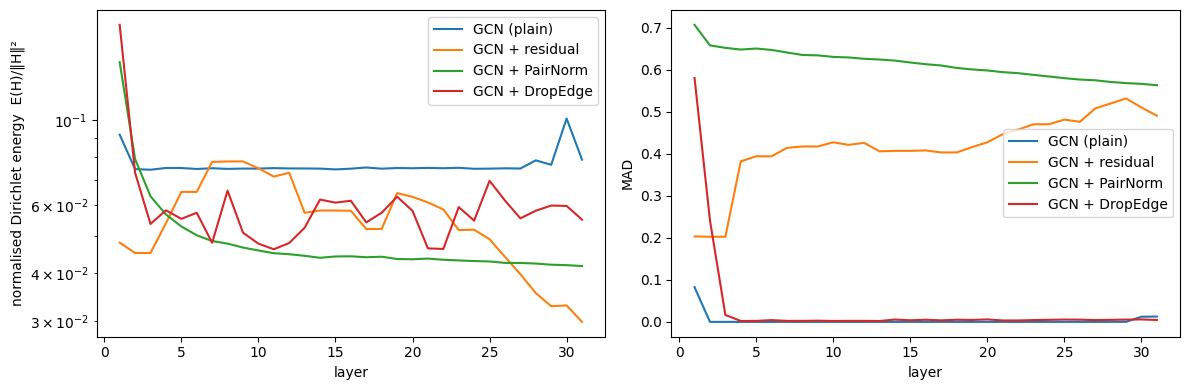

In [19]:
# Layer-wise over-smoothing of the trained 32-layer GCN variants
plot_layerwise({name: trained[name] for name in ['GCN (plain)', 'GCN + residual', 'GCN + PairNorm', 'GCN + DropEdge']})

### 4) GCNII hyper-parameters

GCNII 32 layers | α = 0.0 | λ = 0.1 | Test Acc: 41.40%
GCNII 32 layers | α = 0.0 | λ = 0.5 | Test Acc: 34.60%
GCNII 32 layers | α = 0.0 | λ = 1.0 | Test Acc: 31.50%
GCNII 32 layers | α = 0.1 | λ = 0.1 | Test Acc: 84.20%
GCNII 32 layers | α = 0.1 | λ = 0.5 | Test Acc: 84.20%
GCNII 32 layers | α = 0.1 | λ = 1.0 | Test Acc: 84.30%
GCNII 32 layers | α = 0.5 | λ = 0.1 | Test Acc: 77.70%
GCNII 32 layers | α = 0.5 | λ = 0.5 | Test Acc: 77.80%
GCNII 32 layers | α = 0.5 | λ = 1.0 | Test Acc: 76.10%


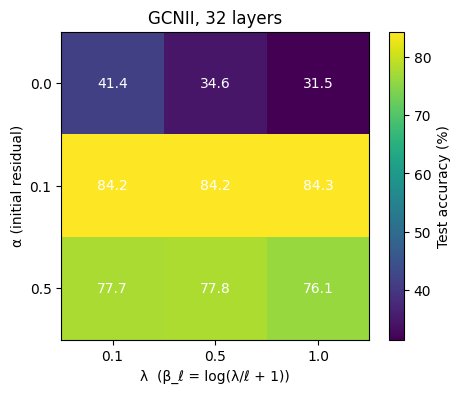

CPU times: user 1min 18s, sys: 117 ms, total: 1min 18s
Wall time: 1min 18s


In [20]:
%%time
alphas, lamdas = [0.0, 0.1, 0.5], [0.1, 0.5, 1.0]
grid = np.zeros((len(alphas), len(lamdas)))
for a_i, a in enumerate(alphas):
    for l_i, lam in enumerate(lamdas):
        set_seed(0)
        model = GCNII(num_features, 64, num_classes, num_layers=32, alpha=a, lamda=lam)
        _, grid[a_i, l_i] = train_model(model, (X, A_hat), epochs=400, optimizer=gcnii_optimizer(model), verbose=False)
        print(f'GCNII 32 layers | α = {a:.1f} | λ = {lam:.1f} | Test Acc: {grid[a_i, l_i]*100:.2f}%')

plt.figure(figsize=(5, 4))
plt.imshow(grid * 100, cmap='viridis')
plt.colorbar(label='Test accuracy (%)')
plt.xticks(range(len(lamdas)), lamdas); plt.yticks(range(len(alphas)), alphas)
plt.xlabel('λ  (β_ℓ = log(λ/ℓ + 1))'); plt.ylabel('α (initial residual)')
for i in range(len(alphas)):
    for j in range(len(lamdas)):
        plt.text(j, i, f'{grid[i, j]*100:.1f}', ha='center', va='center', color='w')
plt.title('GCNII, 32 layers'); plt.show()

### Answers

3) 32-layer comparison (test accuracy, mean ± std over 3 seeds):

| Model (32 layers) | Test accuracy | Hidden layers (see layer-wise plot) |
|---|---|---|
| GCN (plain) | 19.2 ± 2.3 % | MAD ≈ 0 from layer 2: collapsed |
| GCN + residual | 40.7 ± 20.1 % | MAD 0.2–0.5, but training is unstable |
| DeepGCN (res+, GENConv, LayerNorm) | 71.1 ± 2.7 % | trains reliably |
| GCNII | 84.6 ± 0.5 % | better than the 2-layer GCN |
| GCN + PairNorm (+ residual) | 77.9 ± 0.5 % | MAD stays ≈ 0.6–0.7 in every layer |
| GCN + DropEdge (p = 0.5) | 24.5 ± 5.2 % | MAD ≈ 0 from layer 3: collapsed |

The output-layer energy and MAD of the models that fail to train (plain GCN, DropEdge) are not very informative. Their last layer outputs an almost constant vector rescaled by the node degree, which is why the plain GCN's normalised output energy is high (1.07). The hidden-layer plot is the reliable diagnostic: the plain and DropEdge GCNs collapse to MAD ≈ 0 after 2–3 layers, while PairNorm keeps the nodes apart through all 32 layers.

4) GCNII hyper-parameters.
- $\alpha=0$ gives 31–41%. Without the initial residual, GCNII is only a GCN with identity mapping, and it over-smooths like the plain GCN. The initial residual is the key ingredient: every layer re-injects a fraction $\alpha$ of $H^{(0)}$, so the representation can never converge to the stationary subspace.
- $\alpha=0.1$ is best (84.2–84.3%).
- $\alpha=0.5$ drops to 76–78%. Too much teleportation keeps the receptive field effectively at 1–2 hops (close to an MLP on smoothed features).
- $\lambda$ matters little. For deep layers $\beta_\ell=\log(\lambda/\ell+1)\approx\lambda/\ell$ is small anyway, so most layers are close to the identity. This identity mapping is what makes 32–64 layers trainable.

5) What each method addresses.
- Over-smoothing
  - GCNII: the initial residual keeps a component of $H^{(0)}$. GCNII can express a $K$-order polynomial filter with arbitrary coefficients, so it is not forced to be low-pass only.
  - PairNorm: it keeps the total pairwise distance constant (green curve: MAD does not collapse). It only works well together with the residual update of slide 51 (without the residual, PN reaches only 26.6% at 32 layers, see the PracticeCode).
- Optimisation
  - Residual connections (GCN + residual, DeepGCN res/res+) let gradients flow. A plain residual helps (19% → 41%) but is unstable. The pre-activation res+ block with normalisation trains reliably (71%).
- Overfitting / regularisation
  - DropEdge is data augmentation. It also slows down smoothing, because fewer edges mean slower mixing. It improves a 4-layer GCN (73.9% → 77.5% in the PracticeCode), but on its own it does **not** fix the optimisation problem of a 32-layer GCN (24.5%).